In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from statsmodels.tsa.stattools import adfuller, kpss

In [2]:
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

In [3]:
tickers = ["AAPL", "QQQ"]

data = yf.download(
    tickers,
    start="2019-01-01",
    end="2026-10-01",
    auto_adjust=False
)

[*********************100%***********************]  1 of 2 completed


In [4]:
data.head()

Price       Adj Close                  Close                   High  \
Ticker           AAPL         QQQ       AAPL         QQQ       AAPL   
Date                                                                  
2019-01-02  37.436913  147.724457  39.480000  154.880005  39.712502   
2019-01-03  33.707912  142.898224  35.547501  149.820007  36.430000   
2019-01-04  35.146896  149.012039  37.064999  156.229996  37.137501   
2019-01-07  35.068653  150.786087  36.982498  158.089996  37.207500   
2019-01-08  35.737167  152.150070  37.687500  159.520004  37.955002   

Price                         Low                   Open              \
Ticker             QQQ       AAPL         QQQ       AAPL         QQQ   
Date                                                                   
2019-01-02  155.750000  38.557499  150.880005  38.722500  150.990005   
2019-01-03  153.259995  35.500000  149.490005  35.994999  152.600006   
2019-01-04  157.000000  35.950001  151.740005  36.132500  152.339996   
2019-01-07  158.860001  36.474998  156.110001  37.174999  156.619995   
2019-01-08  160.110001  37.130001  157.199997  37.389999  159.539993   

Price          Volume            
Ticker           AAPL       QQQ  
Date                             
2019-01-02  148158800  58576700  
2019-01-03  365248800  74820200  
2019-01-04  234428400  74709300  
2019-01-07  219111200  52059300  
2019-01-08  164101200  49388700

In [5]:
data.tail()

Price        Adj Close                   Close                    High  \
Ticker            AAPL         QQQ        AAPL         QQQ        AAPL   
Date                                                                     
2026-09-24  335.920013  741.099976  335.920013  741.099976  338.910004   
2026-09-25  341.070007  744.500000  341.070007  744.500000  341.670013   
2026-09-28  338.399994  736.530029  338.399994  736.530029  342.989990   
2026-09-29  329.399994  737.929993  329.399994  737.929993  337.089996   
2026-09-30  333.019989  739.770020  333.019989  739.770020  339.500000   

Price                          Low                    Open              \
Ticker             QQQ        AAPL         QQQ        AAPL         QQQ   
Date                                                                     
2026-09-24  742.659973  334.299988  734.619995  336.720001  735.289978   
2026-09-25  745.919983  334.529999  739.640015  336.040009  742.830017   
2026-09-28  741.419983  338.040009  731.630005  340.369995  740.460022   
2026-09-29  740.580017  328.700012  735.340027  336.970001  740.150024   
2026-09-30  745.099976  330.140015  739.460022  330.799988  740.190002   

Price         Volume            
Ticker          AAPL       QQQ  
Date                            
2026-09-24  24733100  29000900  
2026-09-25  30002500  30283800  
2026-09-28  32820800  41775000  
2026-09-29  38478000  27052300  
2026-09-30  49988600  29820400

In [7]:
prices = data["Adj Close"].copy()
volume = data["Volume"].copy()

In [8]:
prices.head()

Ticker,AAPL,QQQ
Date,,
2019-01-02,37.436913,147.724457
2019-01-03,33.707912,142.898224
2019-01-04,35.146896,149.012039
2019-01-07,35.068653,150.786087
2019-01-08,35.737167,152.150070


## les dimensions

In [15]:
print("Nombre de lignes :", len(prices))
print("Nombre de colonnes :", prices.shape[1])

Nombre de lignes : 1947
Nombre de colonnes : 2


In [16]:
print(prices.index.min())
print(prices.index.max())

2019-01-02 00:00:00
2026-09-30 00:00:00


## Valeur manquante

In [11]:
print(prices.isna().sum())

Ticker
AAPL    0
QQQ     0
dtype: int64


In [12]:
print(volume.isna().sum())

Ticker
AAPL    0
QQQ     0
dtype: int64


In [18]:
print("Nombre de dates dupliquées :", prices.index.duplicated().sum())

Nombre de dates dupliquées : 0


In [19]:
print(prices.index.is_monotonic_increasing)

True


## Visualiser les prix

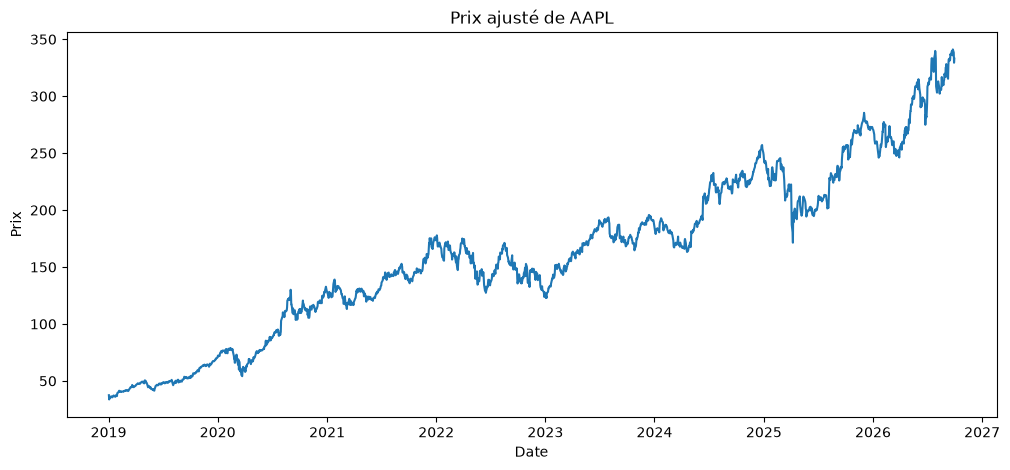

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(prices["AAPL"])
plt.title("Prix ajusté de AAPL")
plt.xlabel("Date")
plt.ylabel("Prix")
plt.show()

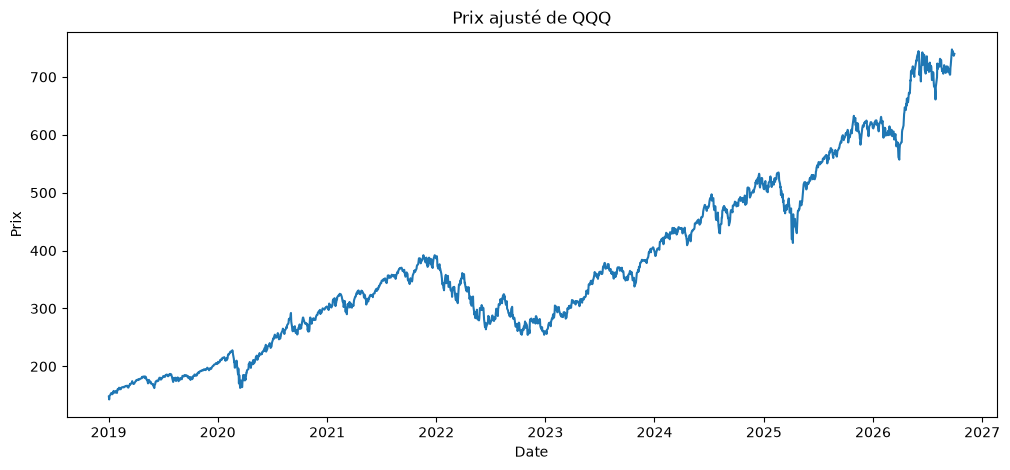

In [21]:
plt.figure(figsize=(12, 5))
plt.plot(prices["QQQ"])
plt.title("Prix ajusté de QQQ")
plt.xlabel("Date")
plt.ylabel("Prix")
plt.show()

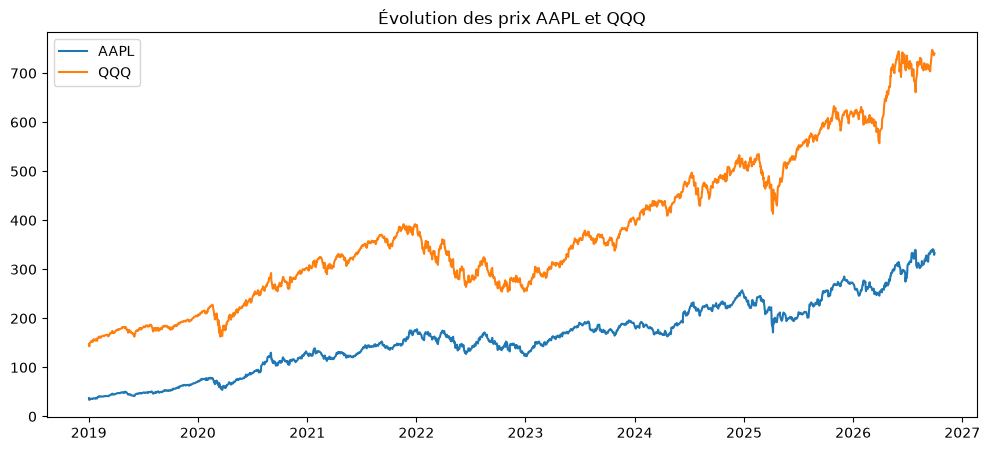

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(prices["AAPL"], label="AAPL")
plt.plot(prices["QQQ"], label="QQQ")
plt.title("Évolution des prix AAPL et QQQ")
plt.legend()
plt.show()

## Créer les rendements logarithmiques
rt​=ln(Pt​/Pt−1​)

In [23]:
returns = np.log(prices / prices.shift(1))

In [24]:
returns = returns.dropna()

In [25]:
returns.head()

Ticker,AAPL,QQQ
Date,,
2019-01-03,-0.104925,-0.033216
2019-01-04,0.041804,0.041894
2019-01-07,-0.002229,0.011835
2019-01-08,0.018884,0.009005
2019-01-09,0.016840,0.008116


## Visualiser les rendements

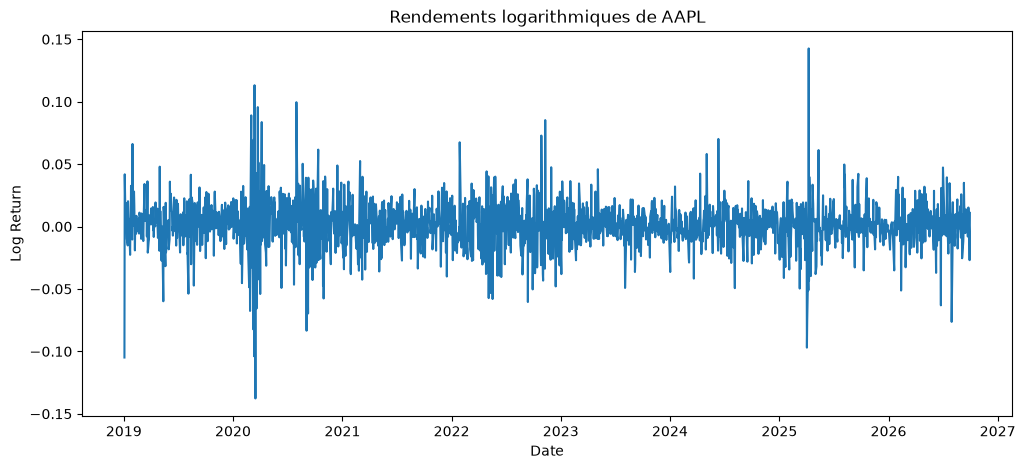

In [26]:
plt.figure(figsize=(12, 5))
plt.plot(returns["AAPL"])
plt.title("Rendements logarithmiques de AAPL")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()

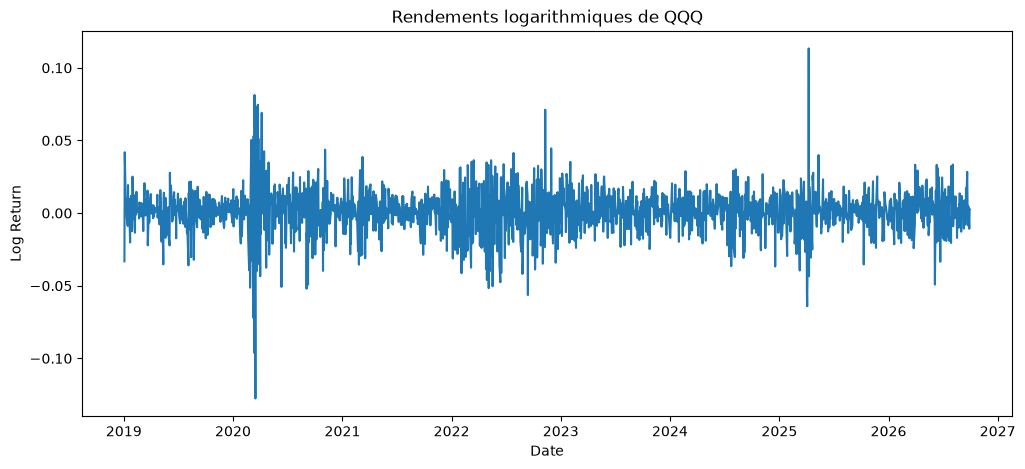

In [27]:
plt.figure(figsize=(12, 5))
plt.plot(returns["QQQ"])
plt.title("Rendements logarithmiques de QQQ")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()

## Créer un indicateur technique

In [28]:
prices["AAPL_MA20"] = prices["AAPL"].rolling(20).mean()

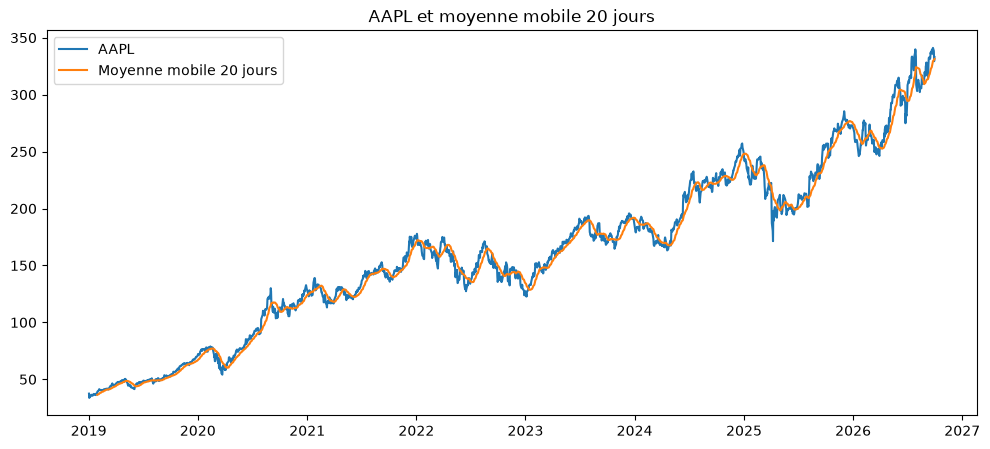

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(prices["AAPL"], label="AAPL")
plt.plot(prices["AAPL_MA20"], label="Moyenne mobile 20 jours")

plt.title("AAPL et moyenne mobile 20 jours")
plt.legend()
plt.show()

## Créer la volatilité réalisée

In [30]:
rolling_volatility = returns["AAPL"].rolling(20).std()

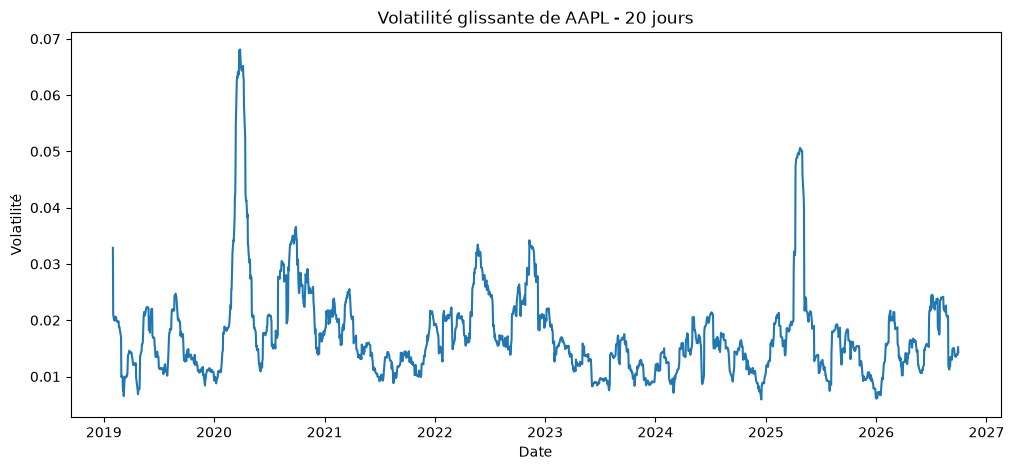

In [31]:
plt.figure(figsize=(12, 5))
plt.plot(rolling_volatility)
plt.title("Volatilité glissante de AAPL - 20 jours")
plt.xlabel("Date")
plt.ylabel("Volatilité")
plt.show()

## Statistiques descriptives

In [32]:
returns["AAPL"].describe()

count    1946.000000
mean        0.001123
std         0.019309
min        -0.137708
25%        -0.007782
50%         0.001301
75%         0.011201
max         0.142617
Name: AAPL, dtype: float64

In [33]:
returns["QQQ"].describe()

count    1946.000000
mean        0.000828
std         0.015073
min        -0.127592
25%        -0.006139
50%         0.001404
75%         0.008745
max         0.113356
Name: QQQ, dtype: float64

In [34]:
print("Skewness AAPL :", returns["AAPL"].skew())
print("Kurtosis AAPL :", returns["AAPL"].kurtosis())

print("Skewness QQQ :", returns["QQQ"].skew())
print("Kurtosis QQQ :", returns["QQQ"].kurtosis())

Skewness AAPL : -0.12014969401553217
Kurtosis AAPL : 6.507937840361199
Skewness QQQ : -0.36573694640005966
Kurtosis QQQ : 7.279885305936318


## Détection des valeurs aberrantes

### Traitement des valeurs aberrantes

Les valeurs extrêmes détectées dans les rendements AAPL et QQQ sont conservées.
Dans le contexte financier, elles peuvent correspondre à de véritables mouvements
du marché et représentent une information importante pour l'analyse de la volatilité.
Une suppression automatique pourrait donc entraîner une perte d'information.

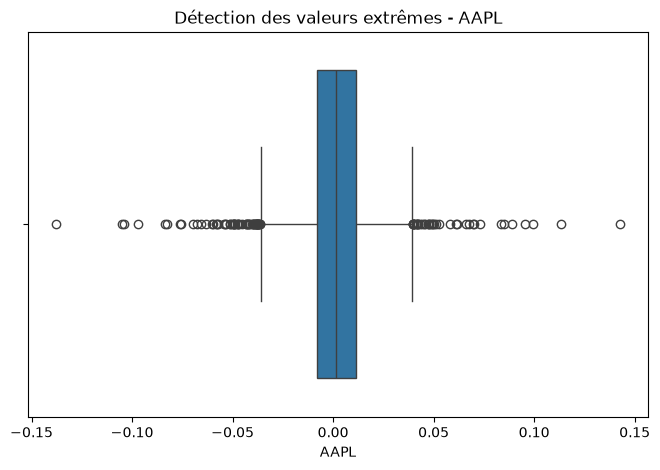

In [35]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=returns["AAPL"])
plt.title("Détection des valeurs extrêmes - AAPL")
plt.show()

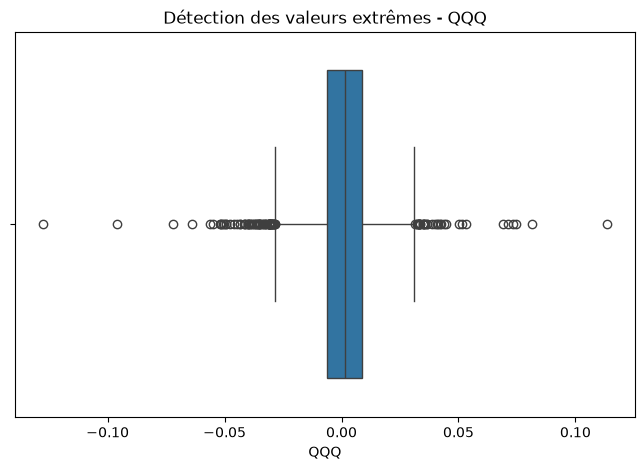

In [36]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=returns["QQQ"])
plt.title("Détection des valeurs extrêmes - QQQ")
plt.show()

In [37]:
dataset = pd.DataFrame({
    "AAPL": prices["AAPL"],
    "QQQ": prices["QQQ"],
    "AAPL_Return": returns["AAPL"],
    "QQQ_Return": returns["QQQ"],
    "AAPL_MA20": prices["AAPL_MA20"],
    "AAPL_Volatility20": rolling_volatility
})

In [38]:
dataset.head()

,AAPL,QQQ,AAPL_Return,QQQ_Return,AAPL_MA20,AAPL_Volatility20
Date,,,,,,
2019-01-02,37.436913,147.724457,NaN,NaN,NaN,NaN
2019-01-03,33.707912,142.898224,-0.104925,-0.033216,NaN,NaN
2019-01-04,35.146896,149.012039,0.041804,0.041894,NaN,NaN
2019-01-07,35.068653,150.786087,-0.002229,0.011835,NaN,NaN
2019-01-08,35.737167,152.150070,0.018884,0.009005,NaN,NaN


In [39]:
dataset.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1947 entries, 2019-01-02 to 2026-09-30
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   AAPL               1947 non-null   float64
 1   QQQ                1947 non-null   float64
 2   AAPL_Return        1946 non-null   float64
 3   QQQ_Return         1946 non-null   float64
 4   AAPL_MA20          1928 non-null   float64
 5   AAPL_Volatility20  1927 non-null   float64
dtypes: float64(6)
memory usage: 106.5 KB


In [40]:
split_index = int(len(dataset) * 0.90)

train = dataset.iloc[:split_index].copy()
test = dataset.iloc[split_index:].copy()

In [41]:
print("Train :", len(train))
print("Test :", len(test))

Train : 1752
Test : 195


In [42]:
print("Train jusqu'à :", train.index[-1])
print("Test à partir de :", test.index[0])

Train jusqu'à : 2025-12-18 00:00:00
Test à partir de : 2025-12-19 00:00:00


## ACF et PACF

In [43]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

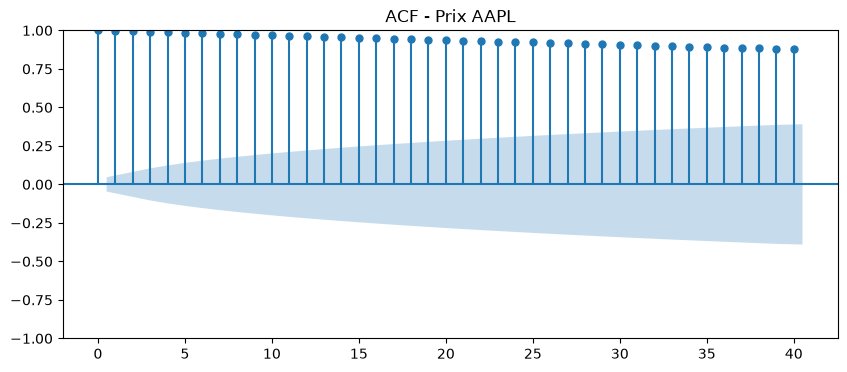

In [44]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["AAPL"].dropna(), ax=ax, lags=40)
plt.title("ACF - Prix AAPL")
plt.show()

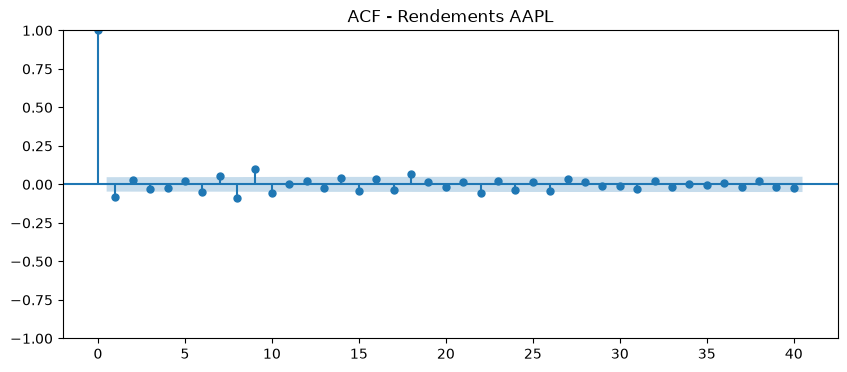

In [45]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["AAPL_Return"].dropna(), ax=ax, lags=40)
plt.title("ACF - Rendements AAPL")
plt.show()

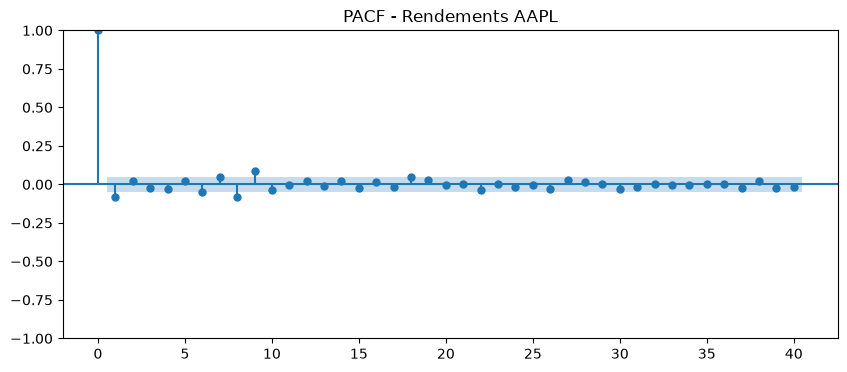

In [46]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(train["AAPL_Return"].dropna(), ax=ax, lags=40)
plt.title("PACF - Rendements AAPL")
plt.show()

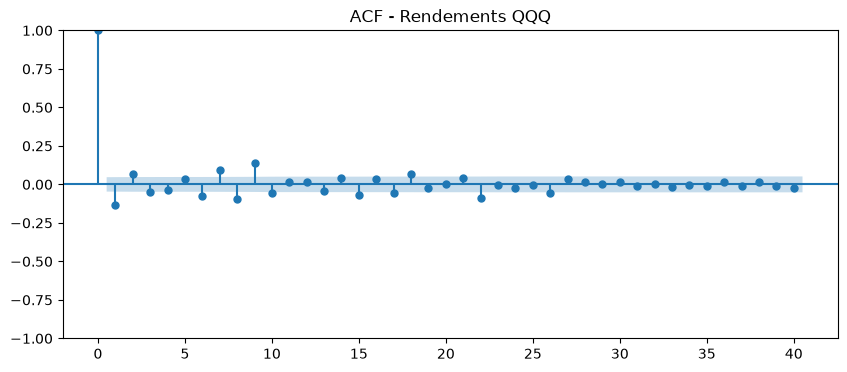

In [54]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(train["QQQ_Return"].dropna(), ax=ax, lags=40)
plt.title("ACF - Rendements QQQ")
plt.show()

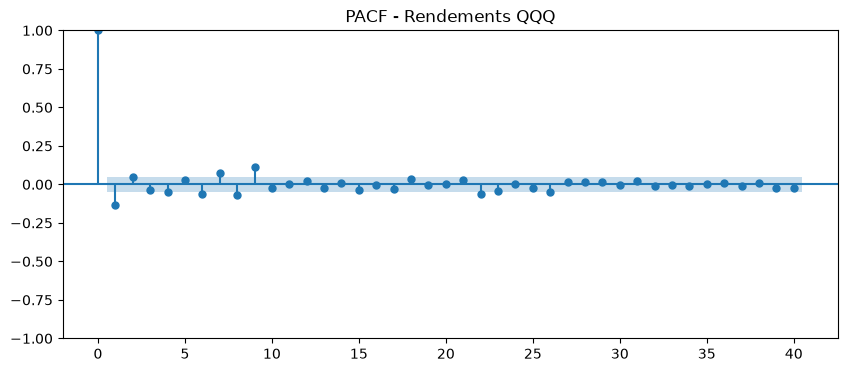

In [55]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(train["QQQ_Return"].dropna(), ax=ax, lags=40)
plt.title("PACF - Rendements QQQ")
plt.show()

## Test ADF

In [47]:
def adf_test(series, name):
    result = adfuller(series.dropna())

    print("Série :", name)
    print("ADF Statistic :", result[0])
    print("p-value :", result[1])

    if result[1] < 0.05:
        print("Conclusion : série stationnaire")
    else:
        print("Conclusion : série non stationnaire")

In [48]:
adf_test(train["AAPL"], "AAPL Prix")
adf_test(train["AAPL_Return"], "AAPL Rendement")

Série : AAPL Prix
ADF Statistic : -0.7299182881936608
p-value : 0.8388471002538459
Conclusion : série non stationnaire
Série : AAPL Rendement
ADF Statistic : -13.575307382194561
p-value : 2.175352246259409e-25
Conclusion : série stationnaire


In [49]:
adf_test(train["QQQ"], "QQQ Prix")
adf_test(train["QQQ_Return"], "QQQ Rendement")

Série : QQQ Prix
ADF Statistic : 0.006537036188912089
p-value : 0.9590693671550397
Conclusion : série non stationnaire
Série : QQQ Rendement
ADF Statistic : -13.206369330189837
p-value : 1.0688027644189787e-24
Conclusion : série stationnaire


## Test KPSS

In [50]:
from statsmodels.tsa.stattools import kpss

In [51]:
def kpss_test(series, name):
    result = kpss(series.dropna(), regression="c", nlags="auto")

    print("Série :", name)
    print("KPSS Statistic :", result[0])
    print("p-value :", result[1])

    if result[1] < 0.05:
        print("Conclusion : série non stationnaire")
    else:
        print("Conclusion : série stationnaire")

In [52]:
kpss_test(train["AAPL"], "AAPL Prix")
kpss_test(train["AAPL_Return"], "AAPL Rendement")

Série : AAPL Prix
KPSS Statistic : 5.997606451489089
p-value : 0.01
Conclusion : série non stationnaire
Série : AAPL Rendement
KPSS Statistic : 0.213507181216168
p-value : 0.1
Conclusion : série stationnaire


In [53]:
kpss_test(train["QQQ"], "QQQ Prix")
kpss_test(train["QQQ_Return"], "QQQ Rendement")

Série : QQQ Prix
KPSS Statistic : 5.491236899862725
p-value : 0.01
Conclusion : série non stationnaire
Série : QQQ Rendement
KPSS Statistic : 0.0902693482629067
p-value : 0.1
Conclusion : série stationnaire


## la décomposition
Pour les prix financiers, la saisonnalité classique est moins évidente, donc on peut faire une décomposition sur les rendements AAPL.

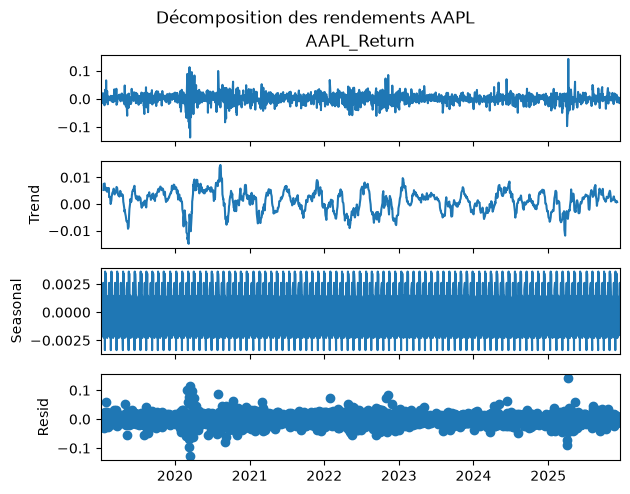

In [56]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    train["AAPL_Return"].dropna(),
    model="additive",
    period=20
)

decomposition.plot()
plt.suptitle("Décomposition des rendements AAPL", y=1.02)
plt.show()

## analyser les ruptures / changements de régime

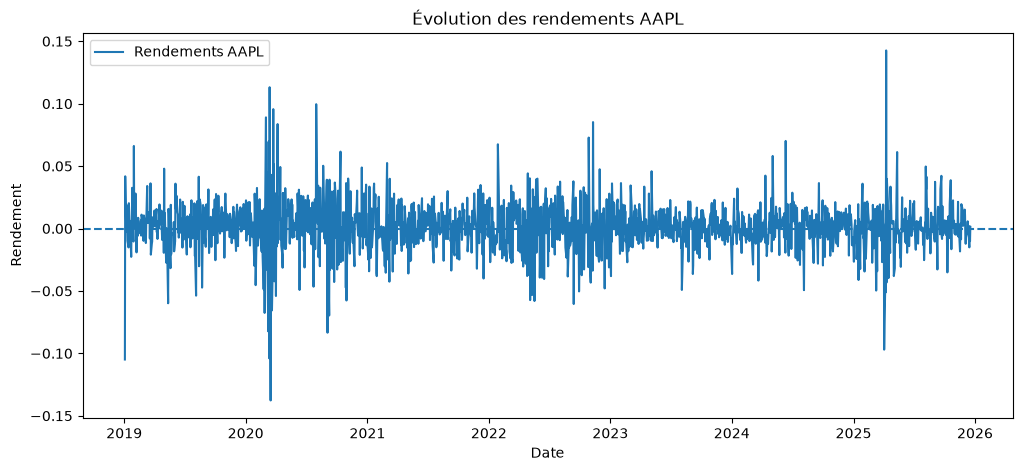

In [57]:
plt.figure(figsize=(12, 5))

plt.plot(train["AAPL_Return"], label="Rendements AAPL")
plt.axhline(0, linestyle="--")

plt.title("Évolution des rendements AAPL")
plt.xlabel("Date")
plt.ylabel("Rendement")
plt.legend()
plt.show()

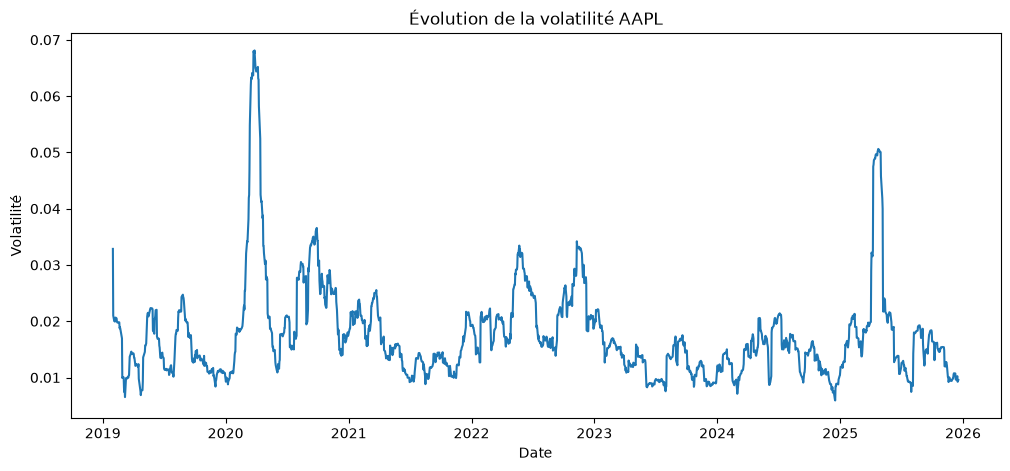

In [58]:
plt.figure(figsize=(12, 5))

plt.plot(train["AAPL_Volatility20"])

plt.title("Évolution de la volatilité AAPL")
plt.xlabel("Date")
plt.ylabel("Volatilité")

plt.show()

## Modèle ARIMA - Identification des paramètres

In [59]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera

In [60]:
from pmdarima import auto_arima

arima_auto = auto_arima(
    train["AAPL"],
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=True
)

print(arima_auto.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=8558.392, Time=3.34 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8555.037, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8556.487, Time=0.07 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=8556.510, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8557.076, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=8559.012, Time=0.13 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0] intercept
Total fit time: 3.858 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1752
Model:               SARIMAX(0, 1, 0)   Log Likelihood               -4275.518
Date:                Wed, 07 Oct 2026   AIC                           8555.037
Time:                        16:53:38   BIC                           8565.973
Sample:                             0   HQIC                          8559.079
          

In [61]:
print("Ordre ARIMA choisi :", arima_auto.order)

Ordre ARIMA choisi : (0, 1, 0)


## Estimation du modèle ARIMA

In [62]:
p, d, q = arima_auto.order

model_arima = ARIMA(
    train["AAPL"],
    order=(p, d, q)
)

arima_result = model_arima.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                 1752
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -4277.538
Date:                Wed, 07 Oct 2026   AIC                           8557.076
Time:                        16:53:59   BIC                           8562.544
Sample:                             0   HQIC                          8559.097
                               - 1752                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         7.7519      0.115     67.404      0.000       7.527       7.977
Ljung-Box (L1) (Q):                   0.55   Jarque-Bera (JB):              5140.77
Prob(Q):                              0.46   Pr

## Diagnostic des résidus ARIMA

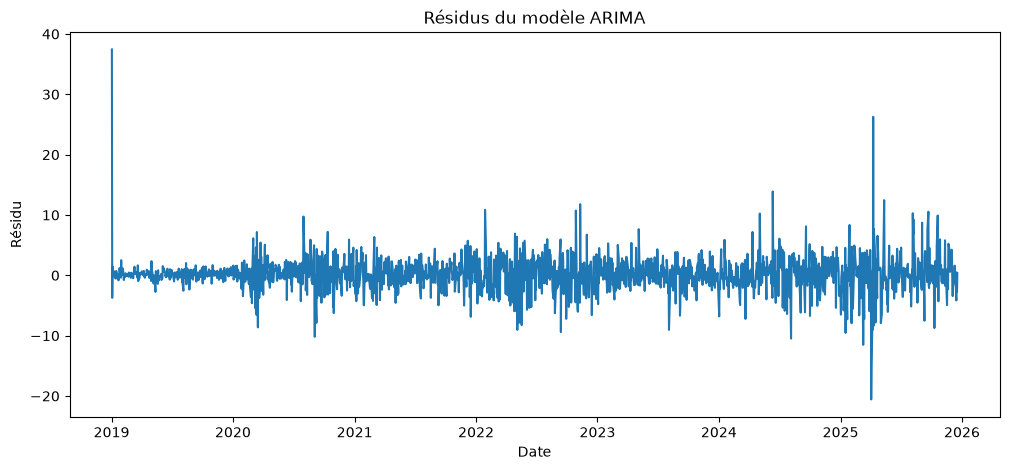

In [63]:
residuals_arima = arima_result.resid

plt.figure(figsize=(12, 5))
plt.plot(residuals_arima)
plt.title("Résidus du modèle ARIMA")
plt.xlabel("Date")
plt.ylabel("Résidu")
plt.show()

In [67]:
#test de Ljung-Box
ljung_box = acorr_ljungbox(
    residuals_arima.dropna(),
    lags=[10, 20],
    return_df=True
)

print(ljung_box)

      lb_stat  lb_pvalue
10  14.404539   0.155326
20  24.504147   0.221063


In [68]:
#Normalité des résidus
jb_stat, jb_pvalue = jarque_bera(residuals_arima.dropna())

print("Jarque-Bera statistic :", jb_stat)
print("p-value :", jb_pvalue)

Jarque-Bera statistic : 34382.57256984467
p-value : 0.0


In [69]:
#ARCH-LM
#vérifier l'hétéroscédasticité.
from statsmodels.stats.diagnostic import het_arch

In [70]:
arch_test = het_arch(residuals_arima.dropna())

print("ARCH-LM statistic :", arch_test[0])
print("p-value :", arch_test[1])

ARCH-LM statistic : 258.192570415202
p-value : 1.026123336519051e-49


## Modèle VAR - AAPL et QQQ

In [71]:
from statsmodels.tsa.api import VAR